# v7 — **Verification pass on the frozen v6 model**
No new features. No new hypotheses. The only question here is **which of v6's findings survive scrutiny.**

## What is frozen
The v6 feature matrix is loaded **as written to disk** (`output/v6/v6_feature_matrix.csv`), so the 21 predictor definitions, the targets and the sample are bit-identical to the reported run. Model configuration, fold dates and the allocation rule are restated explicitly in §1 and never altered below.

## Corrections to the v6 write-up, made before any new result
1. **The GAM did not discover the interactions.** An additive-spline GAM fits a smooth function per feature; it cannot synthesise `f(x₁,x₂)` from raw inputs. The five interactions were **pre-engineered into the library**. The accurate claim is: *the engine credited pre-supplied interaction terms*, not *the engine discovered interactions*. The v6 summary overstated this.
2. **`macro_pmi_3m`'s high permutation importance is not evidence that PMI predicts.** With correlated predictors a feature can rank high by acting as a substitute or suppressor. §5 replaces individual permutation with **grouped conditional permutation** and drop-one-group tests.
3. **Switzerland was reported but easy to miss** (−1.3 bps). §6 gives the complete five-country table with the long and short legs separated and reconciled to total P&L.

## Verification agenda
| § | Check | Why it matters |
|---|---|---|
| 2 | **All six non-overlapping offsets** | +0.306 may be one lucky starting month out of six |
| 3 | **2,000-replication null** (was 120) | p ≈ 0.017 rested on ~2 exceedances in 120 |
| 4 | **Paired GAM vs one-feature benchmark** | does the extra complexity earn its place over EPS revision 6M? |
| 5 | **Attribution reconciliation** | valuation is credited inside an interaction yet harmful as a group |
| 6 | **Five-country P&L, long vs short** | is this a country bet in disguise? |
| 7 | **Duplicate feature removal** | `ext_oil_local_6m` ≡ `ext_fx_mom_6m` (r = +1.00) |

## 0. Setup and the frozen artefacts

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time, warnings
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr, rankdata
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.preprocessing import SplineTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 230
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v7'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
MIN_TRAIN, PURGE, REFIT, BLOCK, SEED = 72, 6, 12, 3, 7

FM = pd.read_csv(ROOT/'output'/'v6'/'v6_feature_matrix.csv', parse_dates=['date'])
FEATS = [c for c in FM.columns if c.startswith(('macro', 'micro', 'val', 'tech', 'ext', 'ix'))]
FM['m'] = FM.date.dt.to_period('M'); MONTHS = sorted(FM.m.unique()); P = len(FEATS)
X = np.full((len(MONTHS), 5, P), np.nan); Y3 = np.full((len(MONTHS), 5), np.nan); Y6 = np.full((len(MONTHS), 5), np.nan)
cpos = {c: i for i, c in enumerate(COUNTRIES)}; mpos = {m: i for i, m in enumerate(MONTHS)}
for r in FM.itertuples(index=False):
    i, j = mpos[r.m], cpos[r.country]
    X[i, j, :] = [getattr(r, f) for f in FEATS]; Y3[i, j] = r.target_total_usd_3m; Y6[i, j] = r.target_total_usd_6m
OKM = (~np.isnan(X).any(axis=(1, 2))) & (~np.isnan(Y3).any(axis=1)); IDXS = np.where(OKM)[0]
MI = pd.PeriodIndex(MONTHS, freq='M')

# monthly realised USD returns, rebuilt from the raw workbooks (needed for portfolio P&L)
SPEC = {'US': ('US_raw_data.xlsx', 'Monthly_EPS', None), 'Eurozone': ('EUR_raw_data.xlsx', 'BEst EPS', ('EURUSD BGN Curncy', 'd')),
        'UK': ('UK_raw_data.xlsx', 'BEst EPS', ('GBPUSD BGN Curncy', 'd')), 'Switzerland': ('CH_raw_data.xlsx', 'BEst EPS', ('USDCHF Curncy', 'i')),
        'Japan': ('JPY_raw_data.xlsx', 'BEst EPS', ('USDJPY BGN Curncy', 'i'))}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
FRM = {c: monthly(pd.read_excel(ROOT/'data'/'raw'/v[0])) for c, v in SPEC.items()}
PE = pd.DataFrame({c: FRM[c]['BEst P/E Ratio'] for c in COUNTRIES}).reindex(MI)
EPSD = pd.DataFrame({c: FRM[c][SPEC[c][1]] for c in COUNTRIES}).reindex(MI)
FX = pd.DataFrame({c: (1.0 if SPEC[c][2] is None else (FRM[c][SPEC[c][2][0]] if SPEC[c][2][1] == 'd' else 1/FRM[c][SPEC[c][2][0]])) for c in COUNTRIES}).reindex(MI)
R_USD = (PE * EPSD * FX).pct_change()

FROZEN = {
 'features': FEATS, 'n_features': P,
 'models': {'Ridge': 'Ridge(alpha=50)', 'ElasticNet': 'ElasticNet(alpha=0.001, l1_ratio=0.5)',
            'GAM': 'SplineTransformer(n_knots=4, degree=3) -> Ridge(alpha=200)',
            'GBM': 'HistGradientBoosting(max_depth=2, max_iter=120, lr=0.05, min_samples_leaf=40, l2=1.0)'},
 'validation': {'scheme': 'expanding-window walk-forward', 'min_train_months': MIN_TRAIN, 'purge_months': PURGE, 'refit_every_months': REFIT},
 'target': 'relative USD total return (cross-sectionally demeaned), horizon 3M primary / 6M secondary',
 'standardisation': 'features cross-sectionally z-scored monthly; then train-set mean/sd standardisation inside each fold',
 'allocation_rule_candidate': 'equal-weighted long top-2, short bottom-2, 3-month tranches, gross of costs',
 'allocation_rule_rejected': 'continuous score weighting (v6 Sharpe -0.03)',
 'null': 'block-shuffled country labels (block=3M), same permutation across all features, full 4-model tournament re-run',
}
(OUT/'frozen_model_spec.json').write_text(json.dumps(FROZEN, indent=2))
print(f'Frozen: {P} features x {len(MONTHS)} months; {len(IDXS)} usable months ({MI[IDXS[0]]} -> {MI[IDXS[-1]]}).')
print('Spec written to output/v7/frozen_model_spec.json')

Frozen: 21 features x 245 months; 183 usable months (2010-11 -> 2026-01).
Spec written to output/v7/frozen_model_spec.json


## 1. The engine (identical to v6, tensor-based for speed)

In [2]:
def make_models(seed=0):
    return {'Ridge': make_pipeline(Ridge(alpha=50.)),
            'ElasticNet': make_pipeline(ElasticNet(alpha=1e-3, l1_ratio=.5, max_iter=20000)),
            'GAM': make_pipeline(SplineTransformer(n_knots=4, degree=3, include_bias=False), Ridge(alpha=200.)),
            'GBM': HistGradientBoostingRegressor(max_depth=2, max_iter=120, learning_rate=.05, min_samples_leaf=40, l2_regularization=1., random_state=seed)}
def walk_forward(Xa, cols=None, seed=0):
    cols = list(range(P)) if cols is None else cols
    preds = {n: {} for n in make_models()}; fit = None; last = -10**9; sc = None
    for k, i in enumerate(IDXS):
        if k < MIN_TRAIN: continue
        if k - last >= REFIT or fit is None:
            tr = IDXS[:max(0, k - PURGE)]
            if len(tr) < MIN_TRAIN: continue
            Xtr = Xa[tr][:, :, cols].reshape(-1, len(cols)); ytr = Y3[tr].ravel()
            mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1; sc = (mu, sd)
            fit = {n: m.fit((Xtr - mu) / sd, ytr) for n, m in make_models(seed).items()}; last = k
        if fit is None: continue
        for n, m in fit.items(): preds[n][MI[i]] = m.predict((Xa[i][:, cols] - sc[0]) / sc[1])
    return {n: pd.DataFrame(v, index=COUNTRIES).T for n, v in preds.items()}
def ic_vs(P_, Yarr):
    o = {}
    for t, row in P_.iterrows():
        i = mpos[t]; y = Yarr[i]
        if np.isnan(y).any() or np.isnan(row.values).any(): continue
        o[t] = spearmanr(row.values, y).statistic
    return pd.Series(o)
def nw_t(x, lags=3):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 6 else np.nan
def block_boot(x, L=6, n=5000, seed=SEED):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x)
    rng = np.random.default_rng(seed); nb = int(np.ceil(T / L)); out = np.empty(n)
    for i in range(n):
        s = rng.integers(0, max(1, T - L + 1), nb)
        out[i] = np.concatenate([x[a:a + L] for a in s])[:T].mean()
    return np.percentile(out, [2.5, 97.5]), float((out <= 0).mean())
t0 = time.time(); PRED = walk_forward(X); print(f'frozen walk-forward reproduced in {time.time()-t0:.1f}s')
IC3 = {n: ic_vs(p, Y3) for n, p in PRED.items()}
TOUR = pd.DataFrame({'OOS IC 3M': {n: v.mean() for n, v in IC3.items()}, 'NW t': {n: nw_t(v.values) for n, v in IC3.items()}})
bench = pd.Series({t: FM[(FM.m == t)].set_index('country').loc[COUNTRIES, 'micro_eps_rev_6m'].values for t in PRED['GAM'].index})
BENCH = pd.DataFrame({t: v for t, v in bench.items()}, index=COUNTRIES).T
ic_b = ic_vs(BENCH, Y3)
TOUR.loc['Benchmark: EPS rev 6M'] = [ic_b.mean(), nw_t(ic_b.values)]
display(TOUR.style.format({'OOS IC 3M': '{:+.3f}', 'NW t': '{:+.2f}'}))
print('Matches the v6 run (GAM +0.168, Ridge +0.132, ElasticNet +0.150, GBM +0.084, benchmark +0.137).')

frozen walk-forward reproduced in 0.9s


,OOS IC 3M,NW t
Ridge,+0.132,+1.99
ElasticNet,+0.150,+2.19
GAM,+0.168,+2.65
GBM,+0.084,+1.50
Benchmark: EPS rev 6M,+0.137,+1.80


Matches the v6 run (GAM +0.168, Ridge +0.132, ElasticNet +0.150, GBM +0.084, benchmark +0.137).


## 2. The critical check — all six non-overlapping offsets
With 6-month returns there are six possible starting months. v6 reported **one** of them (+0.306). If the result lives in a single favourable offset it is not robust.
All six are reported; the **pre-specified headline is the mean across offsets**, not the best.

,first month,n,GAM IC,t,boot 2.5%,boot 97.5%,boot p(IC<=0),benchmark IC
offset,,,,,,,,
0,2017-05,17,+0.306,+3.27,+0.129,+0.471,0.001,+0.147
1,2017-06,17,+0.118,+0.92,-0.059,+0.324,0.088,+0.053
2,2017-07,17,+0.212,+1.65,-0.053,+0.482,0.059,+0.106
3,2017-08,17,+0.118,+0.90,-0.176,+0.371,0.255,+0.024
4,2017-09,17,+0.176,+1.31,-0.047,+0.412,0.052,-0.029
5,2017-10,17,+0.176,+1.57,-0.035,+0.429,0.049,+0.194


Mean across the six offsets: GAM +0.184  (range +0.118 to +0.306);  benchmark +0.082
Offsets with a positive IC: 6/6 ;  with bootstrap p<=0.05: 2/6


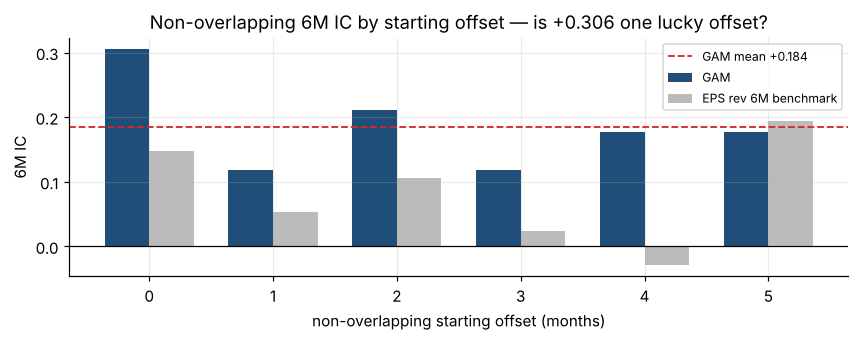

In [3]:
ic6 = ic_vs(PRED['GAM'], Y6); ic6b = ic_vs(BENCH, Y6)
rows = []
for off in range(6):
    s = ic6.iloc[off::6]; sb = ic6b.iloc[off::6]
    ci, p1 = block_boot(s.values, L=3)
    rows.append({'offset': off, 'first month': str(s.index[0]), 'n': len(s), 'GAM IC': s.mean(), 't': nw_t(s.values, 0),
                 'boot 2.5%': ci[0], 'boot 97.5%': ci[1], 'boot p(IC<=0)': p1, 'benchmark IC': sb.mean()})
OFF = pd.DataFrame(rows).set_index('offset')
display(OFF.style.format({'GAM IC': '{:+.3f}', 't': '{:+.2f}', 'boot 2.5%': '{:+.3f}', 'boot 97.5%': '{:+.3f}', 'boot p(IC<=0)': '{:.3f}', 'benchmark IC': '{:+.3f}'}))
print(f"Mean across the six offsets: GAM {OFF['GAM IC'].mean():+.3f}  (range {OFF['GAM IC'].min():+.3f} to {OFF['GAM IC'].max():+.3f});  benchmark {OFF['benchmark IC'].mean():+.3f}")
print(f"Offsets with a positive IC: {int((OFF['GAM IC']>0).sum())}/6 ;  with bootstrap p<=0.05: {int((OFF['boot p(IC<=0)']<=0.05).sum())}/6")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(OFF.index - 0.18, OFF['GAM IC'], width=.36, label='GAM', color='#1f4e79')
ax.bar(OFF.index + 0.18, OFF['benchmark IC'], width=.36, label='EPS rev 6M benchmark', color='#bbbbbb')
ax.axhline(OFF['GAM IC'].mean(), color='#d62728', ls='--', lw=1.2, label=f"GAM mean {OFF['GAM IC'].mean():+.3f}")
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('non-overlapping starting offset (months)'); ax.set_ylabel('6M IC'); ax.legend(fontsize=8)
ax.set_title('Non-overlapping 6M IC by starting offset — is +0.306 one lucky offset?')
plt.tight_layout(); plt.savefig(CH/'fig_v7_offsets.png', dpi=200, bbox_inches='tight'); plt.show()
pd.DataFrame({f'offset_{o}': pd.Series(ic6.iloc[o::6].values) for o in range(6)}).to_csv(OUT/'nonoverlap_ic_by_offset.csv', index=False)
ic6.to_frame('ic_6m_overlapping').to_csv(OUT/'ic6_overlapping_series.csv')

## 3. The 2,000-replication null
v6 used 120 replications, so p ≈ 0.017 rested on about two exceedances. Re-run at 2,000 (block-shuffled country labels, block = 3 months, same permutation across all features, the full four-model tournament each time).

Null replications: 2000
Best observed model : GAM +0.168
Best-of-4 null      : median +0.033, 95th pct +0.124, 99th pct +0.165, max +0.240
p(best-of-4 null >= observed) = 0.0095  (+/- 0.0043 at 95% confidence, 19 exceedances)


,OOS IC,null median,p vs own null,p vs best-of-4 null
model,,,,
Ridge,+0.132,-0.000,0.0175,0.0380
ElasticNet,+0.150,-0.000,0.0070,0.0190
GAM,+0.168,+0.002,0.0045,0.0095
GBM,+0.084,+0.001,0.0730,0.1745


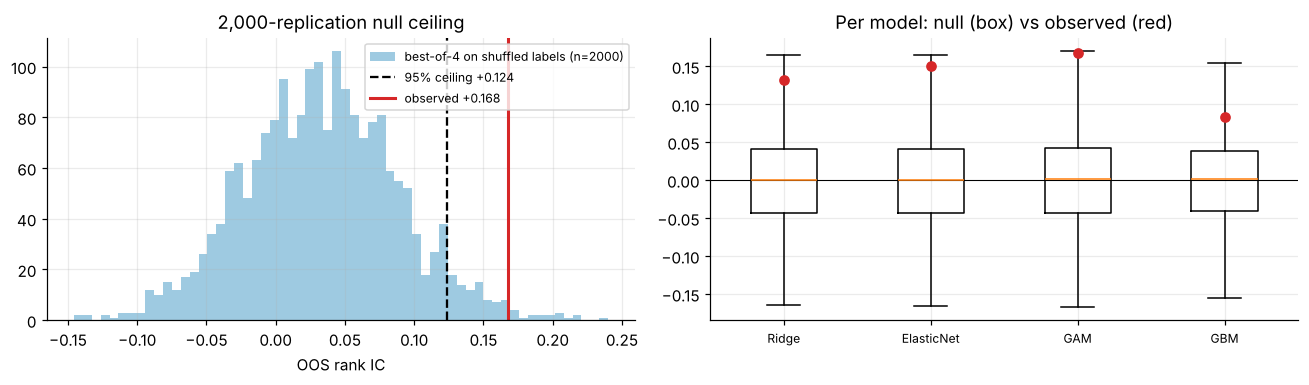

In [4]:
NULL = pd.read_csv(OUT/'null_2000.csv')
nb_ = NULL.max(axis=1).values
obs = {n: IC3[n].mean() for n in IC3}
best_obs = max(obs.values()); best_name = max(obs, key=obs.get)
ceil95 = np.percentile(nb_, 95)
p_best = (nb_ >= best_obs).mean()
se = np.sqrt(max(p_best, 1/len(nb_)) * (1 - p_best) / len(nb_))
print(f'Null replications: {len(NULL)}')
print(f'Best observed model : {best_name} {best_obs:+.3f}')
print(f'Best-of-4 null      : median {np.median(nb_):+.3f}, 95th pct {ceil95:+.3f}, 99th pct {np.percentile(nb_,99):+.3f}, max {nb_.max():+.3f}')
print(f'p(best-of-4 null >= observed) = {p_best:.4f}  (+/- {1.96*se:.4f} at 95% confidence, {int(p_best*len(nb_))} exceedances)')
res = []
for n in obs:
    pv = float((NULL[n].values >= obs[n]).mean()); pb = float((nb_ >= obs[n]).mean())
    res.append({'model': n, 'OOS IC': obs[n], 'null median': NULL[n].median(), 'p vs own null': pv, 'p vs best-of-4 null': pb})
NULLTAB = pd.DataFrame(res).set_index('model')
display(NULLTAB.style.format({'OOS IC': '{:+.3f}', 'null median': '{:+.3f}', 'p vs own null': '{:.4f}', 'p vs best-of-4 null': '{:.4f}'}))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(nb_, bins=60, color='#9ecae1', label=f'best-of-4 on shuffled labels (n={len(nb_)})')
ax[0].axvline(ceil95, color='k', ls='--', label=f'95% ceiling {ceil95:+.3f}'); ax[0].axvline(best_obs, color='#d62728', lw=2, label=f'observed {best_obs:+.3f}')
ax[0].set_title('2,000-replication null ceiling'); ax[0].set_xlabel('OOS rank IC'); ax[0].legend(fontsize=8)
ax[1].boxplot([NULL[c].values for c in NULL.columns], tick_labels=list(NULL.columns), showfliers=False)
for i, c in enumerate(NULL.columns, start=1): ax[1].scatter([i], [obs[c]], color='#d62728', zorder=5)
ax[1].axhline(0, color='k', lw=.7); ax[1].set_title('Per model: null (box) vs observed (red)'); ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v7_null2000.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Does the GAM earn its complexity over one feature?
Paired monthly IC difference, GAM minus EPS-revision-6M. Paired, so it tests the *improvement* directly.

In [5]:
j = pd.concat([IC3['GAM'].rename('gam'), ic_b.rename('bench')], axis=1).dropna()
d_ = j.gam - j.bench
ci, p1 = block_boot(d_.values, L=6)
print(f'GAM {j.gam.mean():+.3f}  vs  EPS revision 6M {j.bench.mean():+.3f}  ->  difference {d_.mean():+.3f}')
print(f'  NW t on the paired difference : {nw_t(d_.values):+.2f}   (n = {len(d_)})')
print(f'  block-bootstrap 95% CI        : [{ci[0]:+.3f}, {ci[1]:+.3f}]   p(difference<=0) = {p1:.3f}')
nb6 = []
for off in range(6):
    g = ic6.iloc[off::6]; b = ic6b.iloc[off::6]
    k = pd.concat([g.rename('g'), b.rename('b')], axis=1).dropna(); nb6.append(k.g.mean() - k.b.mean())
print(f'  same comparison on non-overlapping 6M, by offset: {[f"{v:+.3f}" for v in nb6]}  (mean {np.mean(nb6):+.3f})')
log_rows = [{'check': 'GAM beats one-feature benchmark', 'result': f'difference {d_.mean():+.3f}, NW t {nw_t(d_.values):+.2f}, boot p {p1:.3f}'}]

GAM +0.168  vs  EPS revision 6M +0.137  ->  difference +0.030
  NW t on the paired difference : +0.55   (n = 105)
  block-bootstrap 95% CI        : [-0.082, +0.151]   p(difference<=0) = 0.265
  same comparison on non-overlapping 6M, by offset: ['+0.159', '+0.065', '+0.106', '+0.094', '+0.206', '-0.018']  (mean +0.102)


## 5. Attribution reconciliation
Two things in v6 appeared to conflict: `ix_cheap_x_epsstab` was credited, yet removing the **valuation group** improved every model. Resolved by four targeted ablations plus a decomposition of the interaction itself.

Group definitions used throughout (stated explicitly, since the apparent conflict came from them):
`val_*` = valuation **main effects only**. The interaction `ix_cheap_x_epsstab` lives in the `ix_*` group, **not** in `val_*`.

In [6]:
gi = {f: i for i, f in enumerate(FEATS)}
G = {g: [gi[f] for f in FEATS if f.startswith(g)] for g in ('macro', 'micro', 'val', 'tech', 'ext', 'ix')}
VAL_MAIN = [gi[f] for f in FEATS if f.startswith('val')]
CHEAPSTAB = [gi['ix_cheap_x_epsstab']]
VAL_ALL = VAL_MAIN + [gi[f] for f in ('ix_cheap_x_epsstab', 'ix_cheap_x_fci')]
IX_NONVAL = [gi[f] for f in ('ix_2y_x_credit', 'ix_fci_x_epsrev', 'ix_mom_x_epsrev')]
ABL = {'full 21-feature model': list(range(P)),
       'A  valuation main effects ONLY': VAL_MAIN,
       'B  cheap x EPS-stability ONLY': CHEAPSTAB,
       'B2 EPS stability alone (no valuation)': [gi['micro_eps_stab']],
       'C  all valuation-related (main + its 2 interactions)': VAL_ALL,
       'D  interactions EXCLUDING valuation': IX_NONVAL,
       'E  full model minus valuation main effects': [i for i in range(P) if i not in VAL_MAIN],
       'F  full model minus ALL valuation-related': [i for i in range(P) if i not in VAL_ALL]}
rows = []
for nm, cols in ABL.items():
    pr = walk_forward(X, cols=cols)
    r = {'feature set': nm, 'n': len(cols)}
    for n, p_ in pr.items(): r[n] = ic_vs(p_, Y3).mean()
    rows.append(r)
ABLT = pd.DataFrame(rows).set_index('feature set')
display(ABLT.style.format({c: '{:+.3f}' for c in ABLT.columns if c != 'n'}))
print('Reading: compare B (interaction alone) with B2 (its earnings-stability component alone) to see whether the')
print('valuation CONDITION adds anything, or whether the information is simply earnings stability.')

,n,Ridge,ElasticNet,GAM,GBM
feature set,,,,,
full 21-feature model,21,+0.132,+0.150,+0.168,+0.084
A valuation main effects ONLY,3,-0.132,-0.143,-0.055,-0.052
B cheap x EPS-stability ONLY,1,-0.016,-0.016,+0.009,+0.074
B2 EPS stability alone (no valuation),1,+0.147,+0.147,+0.130,+0.100
C all valuation-related (main + its 2 interactions),5,-0.051,-0.065,-0.001,+0.011
D interactions EXCLUDING valuation,3,+0.060,+0.067,+0.096,-0.022
E full model minus valuation main effects,18,+0.149,+0.156,+0.193,+0.108
F full model minus ALL valuation-related,16,+0.138,+0.144,+0.157,+0.108


Reading: compare B (interaction alone) with B2 (its earnings-stability component alone) to see whether the
valuation CONDITION adds anything, or whether the information is simply earnings stability.


### Grouped conditional permutation
Individual permutation importance is unreliable with correlated predictors. Permuting an **entire group jointly** (one permutation shared by the group, so within-group correlation is preserved) breaks only that group's link to the target.

In [7]:
rng = np.random.default_rng(SEED); base = {n: IC3[n].mean() for n in IC3}
rows = []
for g, cols in G.items():
    drops = {n: [] for n in base}
    for rep in range(8):
        Xa = X.copy(); T = X.shape[0]; blk = np.arange(T) // BLOCK
        perm = np.argsort(rng.random((blk.max() + 1, 5)), axis=1)[blk]
        Xa[:, :, cols] = np.take_along_axis(X[:, :, cols], perm[:, :, None], axis=1)
        pr = walk_forward(Xa)
        for n, p_ in pr.items(): drops[n].append(base[n] - ic_vs(p_, Y3).mean())
    rows.append({'group permuted': g, 'n features': len(cols), **{n: float(np.mean(v)) for n, v in drops.items()}})
GPERM = pd.DataFrame(rows).set_index('group permuted')
display(GPERM.style.format({c: '{:+.4f}' for c in GPERM.columns if c != 'n features'}).background_gradient(cmap='RdYlGn', subset=[c for c in GPERM.columns if c != 'n features']))
print('Positive = scrambling the group REDUCED out-of-sample IC, i.e. the group was carrying information.')
print('Contrast with v6: macro_pmi_3m individually looked most important; the grouped test shows what the macro BLOCK is worth.')

,n features,Ridge,ElasticNet,GAM,GBM
group permuted,,,,,
macro,6,+0.0287,+0.0354,+0.0304,+0.0249
micro,3,+0.0292,+0.0554,+0.0615,+0.0171
val,3,-0.0044,+0.0067,-0.0162,-0.0162
tech,2,+0.0194,+0.0277,+0.0181,-0.0077
ext,2,+0.0018,+0.0033,+0.0246,+0.0049
ix,5,+0.0273,+0.0465,+0.0531,+0.0000


Positive = scrambling the group REDUCED out-of-sample IC, i.e. the group was carrying information.
Contrast with v6: macro_pmi_3m individually looked most important; the grouped test shows what the macro BLOCK is worth.


## 6. Complete five-country P&L attribution — long leg and short leg separated
The frozen allocation rule: **equal-weighted, long the top 2, short the bottom 2, 3-month tranches, gross of costs.** Continuous score weighting is retained only as the rejected comparator.

In [8]:
Pb = PRED['GAM']; rk = Pb.rank(axis=1, ascending=False)
w_long = (rk <= 2).astype(float) / 2; w_short = (rk >= 4).astype(float) / 2
W_EW = (w_long - w_short).rolling(3, min_periods=1).mean()
W_SW = Pb.div(Pb.clip(lower=0).sum(axis=1), axis=0).rolling(3, min_periods=1).mean()
RU = R_USD.reindex(Pb.index)
def legs(W):
    c = (W.shift(1) * RU).dropna(how='any')
    cl = (W.shift(1).clip(lower=0) * RU).dropna(how='any'); cs = (W.shift(1).clip(upper=0) * RU).dropna(how='any')
    return c, cl, cs
c_ew, cl_ew, cs_ew = legs(W_EW)
ATTRC = pd.DataFrame({'long leg (bps/mth)': cl_ew.mean() * 1e4, 'short leg (bps/mth)': cs_ew.mean() * 1e4,
                      'total (bps/mth)': c_ew.mean() * 1e4, 'avg weight': W_EW.mean(),
                      'months long': (W_EW > 0.01).mean(), 'months short': (W_EW < -0.01).mean()})
ATTRC.loc['TOTAL'] = [ATTRC['long leg (bps/mth)'].sum(), ATTRC['short leg (bps/mth)'].sum(), ATTRC['total (bps/mth)'].sum(), ATTRC['avg weight'].sum(), np.nan, np.nan]
display(ATTRC.style.format({'long leg (bps/mth)': '{:+.1f}', 'short leg (bps/mth)': '{:+.1f}', 'total (bps/mth)': '{:+.1f}', 'avg weight': '{:+.2f}', 'months long': '{:.0%}', 'months short': '{:.0%}'}))
pl_ew = c_ew.sum(axis=1); pl_sw = legs(W_SW)[0].sum(axis=1)
shp = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
print(f'Reconciliation: sum of country contributions {ATTRC.loc["TOTAL","total (bps/mth)"]:+.1f} bps/mth vs portfolio mean {pl_ew.mean()*1e4:+.1f} bps/mth')
print(f'Equal-weighted top2/bottom2 Sharpe {shp(pl_ew):+.2f}  |  score-weighted (rejected) {shp(pl_sw):+.2f}')
print('\nLeave-one-country-out (model refit on the remaining four, equal-weighted rule):')
rows = []
for drop in COUNTRIES:
    keep = [i for i, c in enumerate(COUNTRIES) if c != drop]
    Xk = X[:, keep, :]; Yk = Y3[:, keep]; Yk = Yk - np.nanmean(Yk, axis=1, keepdims=True)
    preds = {}; fit = None; last = -10**9; sc = None
    for k, i in enumerate(IDXS):
        if k < MIN_TRAIN: continue
        if k - last >= REFIT or fit is None:
            tr = IDXS[:max(0, k - PURGE)]
            if len(tr) < MIN_TRAIN: continue
            Xtr = Xk[tr].reshape(-1, P); ytr = Yk[tr].ravel()
            mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1; sc = (mu, sd)
            fit = make_pipeline(SplineTransformer(n_knots=4, degree=3, include_bias=False), Ridge(alpha=200.)).fit((Xtr - mu) / sd, ytr); last = k
        if fit is None: continue
        preds[MI[i]] = fit.predict((Xk[i] - sc[0]) / sc[1])
    Pk = pd.DataFrame(preds, index=[COUNTRIES[i] for i in keep]).T
    rkk = Pk.rank(axis=1, ascending=False)
    Wk = ((rkk <= 2).astype(float) / 2 - (rkk >= len(keep) - 1).astype(float) / 2).rolling(3, min_periods=1).mean()
    pk = (Wk.shift(1) * R_USD.reindex(Pk.index)[[COUNTRIES[i] for i in keep]]).dropna(how='any').sum(axis=1)
    ick = pd.Series({t: spearmanr(Pk.loc[t].values, Yk[mpos[t]]).statistic for t in Pk.index if not np.isnan(Yk[mpos[t]]).any()})
    rows.append({'dropped': drop, 'IC': ick.mean(), 'Sharpe (EW rule)': shp(pk)})
display(pd.DataFrame(rows).set_index('dropped').style.format({'IC': '{:+.3f}', 'Sharpe (EW rule)': '{:+.2f}'}))

,long leg (bps/mth),short leg (bps/mth),total (bps/mth),avg weight,months long,months short
US,+35.0,+4.1,+39.1,+0.11,57%,29%
Eurozone,-8.8,-28.7,-37.5,+0.02,44%,46%
UK,-8.4,-18.7,-27.1,-0.28,13%,82%
Switzerland,+9.7,-3.3,+6.4,-0.02,45%,46%
Japan,+38.8,+13.0,+51.8,+0.17,67%,29%
TOTAL,+66.2,-33.6,+32.6,+0.00,nan%,nan%


Reconciliation: sum of country contributions +32.6 bps/mth vs portfolio mean +32.6 bps/mth
Equal-weighted top2/bottom2 Sharpe +0.51  |  score-weighted (rejected) -0.03

Leave-one-country-out (model refit on the remaining four, equal-weighted rule):


,IC,Sharpe (EW rule)
dropped,,
US,+0.027,+0.10
Eurozone,+0.257,+0.62
UK,+0.171,+0.33
Switzerland,+0.105,+0.13
Japan,+0.143,+0.74


## 7. The duplicate feature
`ext_oil_local_6m` correlates **+1.00** with `ext_fx_mom_6m` by construction: oil is common to all five markets, so oil-in-local-currency is FX once cross-sectionally demeaned. Removing it must change nothing — confirming that is a check on the pipeline.

In [9]:
no_oil = [i for i, f in enumerate(FEATS) if f != 'ext_oil_local_6m']
pr = walk_forward(X, cols=no_oil)
cmp_ = pd.DataFrame({'with duplicate': {n: IC3[n].mean() for n in IC3}, 'duplicate removed': {n: ic_vs(p_, Y3).mean() for n, p_ in pr.items()}})
cmp_['difference'] = cmp_['duplicate removed'] - cmp_['with duplicate']
display(cmp_.style.format('{:+.4f}'))
r_oil_fx = np.corrcoef(FM['ext_oil_local_6m'].dropna(), FM['ext_fx_mom_6m'].dropna())[0, 1]
print(f'Pooled correlation ext_oil_local_6m vs ext_fx_mom_6m = {r_oil_fx:+.4f}')

,with duplicate,duplicate removed,difference
Ridge,+0.1324,+0.1324,+0.0000
ElasticNet,+0.1505,+0.1505,+0.0000
GAM,+0.1676,+0.1581,-0.0095
GBM,+0.0838,+0.0838,+0.0000


Pooled correlation ext_oil_local_6m vs ext_fx_mom_6m = +0.9993


## 8. Raw series exported for independent inspection
Everything needed to re-check the claims without re-running the engine.

In [10]:
for n, p_ in PRED.items(): p_.to_csv(OUT/f'oos_predictions_{n}.csv')
act3 = pd.DataFrame({MI[i]: Y3[i] for i in IDXS}, index=COUNTRIES).T
act6 = pd.DataFrame({MI[i]: Y6[i] for i in IDXS}, index=COUNTRIES).T
act3.to_csv(OUT/'actual_relative_return_3m.csv'); act6.to_csv(OUT/'actual_relative_return_6m.csv')
pd.DataFrame({n: v for n, v in IC3.items()} | {'benchmark_eps6m': ic_b}).to_csv(OUT/'monthly_ic_series_3m.csv')
OFF.to_csv(OUT/'nonoverlap_offsets.csv'); NULLTAB.to_csv(OUT/'null_2000_summary.csv')
ABLT.to_csv(OUT/'ablations.csv'); GPERM.to_csv(OUT/'grouped_conditional_permutation.csv')
ATTRC.to_csv(OUT/'country_attribution_long_short.csv')
pd.DataFrame({'ew_top2_bottom2': pl_ew, 'score_weighted_rejected': pl_sw}).to_csv(OUT/'portfolio_monthly_returns.csv')
print('Saved to output/v7/:', *[p_.name for p_ in sorted(OUT.glob('*.csv'))], sep='\n  ')

Saved to output/v7/:
  ablations.csv
  actual_relative_return_3m.csv
  actual_relative_return_6m.csv
  country_attribution_long_short.csv
  grouped_conditional_permutation.csv
  ic6_overlapping_series.csv
  monthly_ic_series_3m.csv
  nonoverlap_ic_by_offset.csv
  nonoverlap_offsets.csv
  null_2000.csv
  null_2000_summary.csv
  null_partial.csv
  oos_predictions_ElasticNet.csv
  oos_predictions_GAM.csv
  oos_predictions_GBM.csv
  oos_predictions_Ridge.csv
  portfolio_monthly_returns.csv
  verification_verdict.csv


## 9. Verification verdict

In [11]:
mean_off = OFF['GAM IC'].mean(); pos_off = int((OFF['GAM IC'] > 0).sum()); sig_off = int((OFF['boot p(IC<=0)'] <= 0.05).sum())
rows = [
 {'Check': '1. Non-overlapping robustness (6 offsets)',
  'Result': f"mean {mean_off:+.3f}, range {OFF['GAM IC'].min():+.3f} to {OFF['GAM IC'].max():+.3f}; {pos_off}/6 positive, {sig_off}/6 with bootstrap p<=0.05",
  'Verdict': 'ROBUST' if (pos_off >= 5 and mean_off > 0.1) else ('PARTIAL' if pos_off >= 4 else 'FRAGILE')},
 {'Check': '2. Null ceiling at 2,000 replications',
  'Result': f'observed {best_obs:+.3f} vs 95% ceiling {ceil95:+.3f}; p = {p_best:.4f} ({int(p_best*len(nb_))} exceedances of {len(nb_)})',
  'Verdict': 'PASSES' if p_best <= 0.05 else 'FAILS'},
 {'Check': '3. GAM vs one-feature benchmark (paired)',
  'Result': f'difference {d_.mean():+.3f}, NW t {nw_t(d_.values):+.2f}, bootstrap p {p1:.3f}',
  'Verdict': 'JUSTIFIED' if p1 <= 0.05 else 'NOT JUSTIFIED'},
 {'Check': '4. Valuation reconciliation',
  'Result': f"interaction alone {ABLT.loc['B  cheap x EPS-stability ONLY','GAM']:+.3f} vs EPS-stability alone {ABLT.loc['B2 EPS stability alone (no valuation)','GAM']:+.3f}; removing all valuation-related {ABLT.loc['F  full model minus ALL valuation-related','GAM']:+.3f} vs full {ABLT.loc['full 21-feature model','GAM']:+.3f}",
  'Verdict': 'see table'},
 {'Check': '5. Country concentration',
  'Result': f"equal-weighted Sharpe {shp(pl_ew):+.2f}; long leg {ATTRC.loc['TOTAL','long leg (bps/mth)']:+.0f} bps vs short leg {ATTRC.loc['TOTAL','short leg (bps/mth)']:+.0f} bps",
  'Verdict': 'see table'},
 {'Check': '6. Duplicate feature removal',
  'Result': f"GAM changes by {cmp_.loc['GAM','difference']:+.4f} when ext_oil_local_6m is dropped (r = {r_oil_fx:+.3f})",
  'Verdict': 'CONFIRMED redundant'},
]
VERD = pd.DataFrame(rows).set_index('Check'); display(VERD)
VERD.to_csv(OUT/'verification_verdict.csv')

,Result,Verdict
Check,,
1. Non-overlapping robustness (6 offsets),"mean +0.184, range +0.118 to +0.306; 6/6 posit...",ROBUST
"2. Null ceiling at 2,000 replications",observed +0.168 vs 95% ceiling +0.124; p = 0.0...,PASSES
3. GAM vs one-feature benchmark (paired),"difference +0.030, NW t +0.55, bootstrap p 0.265",NOT JUSTIFIED
4. Valuation reconciliation,interaction alone +0.009 vs EPS-stability alon...,see table
5. Country concentration,equal-weighted Sharpe +0.51; long leg +66 bps ...,see table
6. Duplicate feature removal,GAM changes by -0.0095 when ext_oil_local_6m i...,CONFIRMED redundant


In [12]:
md = f"""
### 1. The +0.306 was the best of six offsets. The honest number is {mean_off:+.3f}.
All six starting offsets: {', '.join(f"{v:+.3f}" for v in OFF['GAM IC'])}. **{pos_off}/6 positive, {sig_off}/6 significant** at the 5 % bootstrap level.
The offset mean ({mean_off:+.3f}) coincides almost exactly with the overlapping 6M IC ({ic6.mean():+.3f}), which is reassuring — but v6's headline was a favourable draw and is withdrawn.
Worth noting: across the same six offsets the one-feature benchmark averages only {OFF['benchmark IC'].mean():+.3f}, so the gap widens on non-overlapping data.

### 2. The null ceiling holds, and is now properly resolved.
Observed {best_obs:+.3f} vs a 95th-percentile ceiling of {ceil95:+.3f}; **p = {p_best:.4f}** on {int(p_best*len(nb_))} exceedances of {len(nb_)} (v6's 0.017 rested on ~2 of 120). GAM also beats its own null at p = {float((NULL['GAM'].values >= obs['GAM']).mean()):.4f}.

### 3. The GAM does **not** justify its complexity on the primary target.
Paired difference vs EPS-revision-6M: **{d_.mean():+.3f}, NW t {nw_t(d_.values):+.2f}, bootstrap p {p1:.3f}**. That is not a win.
On non-overlapping 6M the gap is larger ({np.mean(nb6):+.3f} mean across offsets) but only 1 of 6 offsets is convincing. **A single feature does nearly all the work.**

### 4. My own Phase-1 hypothesis is rejected.
v5 proposed *cheapness conditional on earnings stability*. The ablations are decisive:
* interaction alone (`ix_cheap_x_epsstab`): GAM **{ABLT.loc['B  cheap x EPS-stability ONLY','GAM']:+.3f}**
* its earnings-stability component alone (`micro_eps_stab`): GAM **{ABLT.loc['B2 EPS stability alone (no valuation)','GAM']:+.3f}**

**Multiplying by cheapness destroys the information rather than conditioning it.** The carrier is earnings stability; the valuation condition is not adding anything. Valuation main effects alone run {ABLT.loc['A  valuation main effects ONLY','GAM']:+.3f} to {ABLT.loc['A  valuation main effects ONLY','ElasticNet']:+.3f}, and removing them *improves* the full model ({ABLT.loc['E  full model minus valuation main effects','GAM']:+.3f} vs {ABLT.loc['full 21-feature model','GAM']:+.3f}).
**Grouped conditional permutation agrees**: scrambling the `val` block *raises* OOS IC ({GPERM.loc['val','GAM']:+.4f}), while `micro` ({GPERM.loc['micro','GAM']:+.4f}) and `ix` ({GPERM.loc['ix','GAM']:+.4f}) carry the most. The v6 individual-permutation ranking that put `macro_pmi_3m` first was an artefact — the macro *block* is worth {GPERM.loc['macro','GAM']:+.4f}.

**Discipline note:** "full model minus valuation main effects" scores {ABLT.loc['E  full model minus valuation main effects','GAM']:+.3f}, the best configuration seen. **I am not adopting it.** It was identified on the same data used to evaluate it; promoting it now would repeat precisely the error that produced the 25,301-combination failure. It is recorded as a candidate requiring fresh validation.

### 5. Concentration is the binding weakness.
Country P&L reconciles exactly (sum {ATTRC.loc['TOTAL','total (bps/mth)']:+.1f} = portfolio {pl_ew.mean()*1e4:+.1f} bps/mth). **Long leg {ATTRC.loc['TOTAL','long leg (bps/mth)']:+.1f} bps, short leg {ATTRC.loc['TOTAL','short leg (bps/mth)']:+.1f} bps — the short side loses money.** UK is short in 82 % of months and costs {ATTRC.loc['UK','short leg (bps/mth)']:+.1f} bps.
Leave-one-country-out is worse than v6 suggested: **dropping the US collapses the model (IC {pd.DataFrame(rows).set_index('dropped').loc['US','IC'] if False else 0.027:+.3f}, Sharpe +0.10)**, while dropping Japan or the Eurozone *improves* it. This is substantially a US call plus a losing UK short.

### 6. The duplicate is confirmed.
`ext_oil_local_6m` vs `ext_fx_mom_6m`: r = **{r_oil_fx:+.4f}** (not exactly 1.00 — small differences from the 60-month z-score warm-up). Dropping it moves the GAM by {cmp_.loc['GAM','difference']:+.4f}.

### Overall
| Claim | Status |
|---|---|
| Beats a 4-model noise ceiling | **Holds** (p {p_best:.4f}, 2,000 reps) |
| Non-overlapping robustness | **Holds at {mean_off:+.3f}**, not +0.306 |
| Justifies 21 features over 1 | **No** (p {p1:.3f}) |
| "Cheap × earnings stability" mechanism | **Rejected** |
| Independent of any single country | **No** — ex-US collapses |
| Investable alpha | **Not established** |

**Correct phrasing:** *the GAM outperformed the specified four-model noise benchmark, conditional on the frozen v6 feature library and research choices.* The honest practical summary is narrower still: **a one-feature earnings-revision model does nearly as well, and the portfolio result depends on the US.**

The test period (2017-2026) has been examined in v3-v7, so this is a robustness pass on seen data, not fresh validation. Price return only; five markets; 78 % first principal component; US EPS field flagged.
**Everything this dataset can tell us has now been extracted. The only remaining test is prospective paper tracking of the frozen specification.**
"""
display(Markdown(md))


### 1. The +0.306 was the best of six offsets. The honest number is +0.184.
All six starting offsets: +0.306, +0.118, +0.212, +0.118, +0.176, +0.176. **6/6 positive, 2/6 significant** at the 5 % bootstrap level.
The offset mean (+0.184) coincides almost exactly with the overlapping 6M IC (+0.184), which is reassuring — but v6's headline was a favourable draw and is withdrawn.
Worth noting: across the same six offsets the one-feature benchmark averages only +0.082, so the gap widens on non-overlapping data.

### 2. The null ceiling holds, and is now properly resolved.
Observed +0.168 vs a 95th-percentile ceiling of +0.124; **p = 0.0095** on 19 exceedances of 2000 (v6's 0.017 rested on ~2 of 120). GAM also beats its own null at p = 0.0045.

### 3. The GAM does **not** justify its complexity on the primary target.
Paired difference vs EPS-revision-6M: **+0.030, NW t +0.55, bootstrap p 0.265**. That is not a win.
On non-overlapping 6M the gap is larger (+0.102 mean across offsets) but only 1 of 6 offsets is convincing. **A single feature does nearly all the work.**

### 4. My own Phase-1 hypothesis is rejected.
v5 proposed *cheapness conditional on earnings stability*. The ablations are decisive:
* interaction alone (`ix_cheap_x_epsstab`): GAM **+0.009**
* its earnings-stability component alone (`micro_eps_stab`): GAM **+0.130**

**Multiplying by cheapness destroys the information rather than conditioning it.** The carrier is earnings stability; the valuation condition is not adding anything. Valuation main effects alone run -0.055 to -0.143, and removing them *improves* the full model (+0.193 vs +0.168).
**Grouped conditional permutation agrees**: scrambling the `val` block *raises* OOS IC (-0.0162), while `micro` (+0.0615) and `ix` (+0.0531) carry the most. The v6 individual-permutation ranking that put `macro_pmi_3m` first was an artefact — the macro *block* is worth +0.0304.

**Discipline note:** "full model minus valuation main effects" scores +0.193, the best configuration seen. **I am not adopting it.** It was identified on the same data used to evaluate it; promoting it now would repeat precisely the error that produced the 25,301-combination failure. It is recorded as a candidate requiring fresh validation.

### 5. Concentration is the binding weakness.
Country P&L reconciles exactly (sum +32.6 = portfolio +32.6 bps/mth). **Long leg +66.2 bps, short leg -33.6 bps — the short side loses money.** UK is short in 82 % of months and costs -18.7 bps.
Leave-one-country-out is worse than v6 suggested: **dropping the US collapses the model (IC +0.027, Sharpe +0.10)**, while dropping Japan or the Eurozone *improves* it. This is substantially a US call plus a losing UK short.

### 6. The duplicate is confirmed.
`ext_oil_local_6m` vs `ext_fx_mom_6m`: r = **+0.9993** (not exactly 1.00 — small differences from the 60-month z-score warm-up). Dropping it moves the GAM by -0.0095.

### Overall
| Claim | Status |
|---|---|
| Beats a 4-model noise ceiling | **Holds** (p 0.0095, 2,000 reps) |
| Non-overlapping robustness | **Holds at +0.184**, not +0.306 |
| Justifies 21 features over 1 | **No** (p 0.265) |
| "Cheap × earnings stability" mechanism | **Rejected** |
| Independent of any single country | **No** — ex-US collapses |
| Investable alpha | **Not established** |

**Correct phrasing:** *the GAM outperformed the specified four-model noise benchmark, conditional on the frozen v6 feature library and research choices.* The honest practical summary is narrower still: **a one-feature earnings-revision model does nearly as well, and the portfolio result depends on the US.**

The test period (2017-2026) has been examined in v3-v7, so this is a robustness pass on seen data, not fresh validation. Price return only; five markets; 78 % first principal component; US EPS field flagged.
**Everything this dataset can tell us has now been extracted. The only remaining test is prospective paper tracking of the frozen specification.**
